In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import time
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from collections import OrderedDict

In [2]:
# Load Fashion MNIST dataset
transform = transforms.ToTensor()
train = torchvision.datasets.FashionMNIST(root='./', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train, batch_size=100, shuffle=True)

model_1 = torch.nn.Sequential(OrderedDict([
    ('Input', nn.Linear(in_features=28*28, out_features=128)),
    ('activation', nn.ReLU()),
    ('Hidden', nn.Linear(in_features=128, out_features=10))
]))


opt = optim.SGD(model_1.parameters(), lr=0.1, weight_decay=1e-5)
loss_func = nn.CrossEntropyLoss()

In [3]:
for epoch in range(40):    
    for x, y in train_loader:
        input = x.view(-1, 28*28)

        # Forward Pass
        output = model_1(input)

        # Loss + L2 Regularization
        loss = loss_func(output, y) + 1e-4 * sum(torch.pow(p, 2).sum() for p in model_1.parameters())

        # Backprop
        opt.zero_grad()
        loss.backward()
        
        # Optimize
        opt.step()

In [4]:
model_2 = torch.nn.Sequential(OrderedDict([
    ('Input', nn.Linear(in_features=28*28, out_features=48)),
    ('activation', nn.ReLU()),
    ('dropout', nn.Dropout(0.2)),
    ('Hidden', nn.Linear(in_features=48, out_features=10))
]))

opt = optim.SGD(model_1.parameters(), lr=0.01, weight_decay=1e-5)
loss_func = nn.CrossEntropyLoss()

In [5]:
for epoch in range(40):    
    for x, y in train_loader:
        input = x.view(-1, 28*28)

        # Forward Pass
        output = model_2(input)

        # Loss + L2 Regularization
        loss = loss_func(output, y) + 1e-4 * sum(torch.pow(p, 2).sum() for p in model_2.parameters())

        # Backprop
        opt.zero_grad()
        loss.backward()
        
        # Optimize
        opt.step()

In [6]:
test = torchvision.datasets.FashionMNIST(root='./', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test, batch_size=100, shuffle=True)
m1_avg_acc = []
for x, y in test_loader:
    model_1.eval()
    with torch.no_grad():
        output = model_1(x.view(-1, 28*28))
        y_pred = torch.max(output, 1)[1]
        m1_avg_acc.append(100 * (y_pred == y).sum().item() / len(y))
print(np.mean(m1_avg_acc))
m2_avg_acc = []
for x, y in test_loader:
    model_2.eval()
    with torch.no_grad():
        output = model_2(x.view(-1, 28*28))
        y_pred = torch.max(output, 1)[1]
        m2_avg_acc.append(100 * (y_pred == y).sum().item() / len(y))
print(np.mean(m1_avg_acc))
print(m1_avg_acc == m2_avg_acc)

88.97
88.97
False


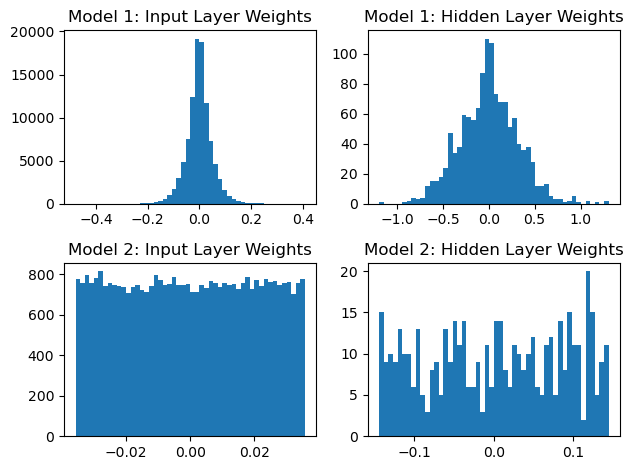

In [7]:
plt.figure()

plt.subplot(2, 2, 1)
plt.hist(model_1.Input.weight.detach().numpy().flatten(), bins=50)
plt.title('Model 1: Input Layer Weights')

plt.subplot(2, 2, 2)
plt.hist(model_1.Hidden.weight.detach().numpy().flatten() , bins=50)
plt.title('Model 1: Hidden Layer Weights')

plt.subplot(2, 2, 3)
plt.hist(model_2.Input.weight.detach().numpy().flatten(), bins=50)
plt.title('Model 2: Input Layer Weights')

plt.subplot(2, 2, 4)
plt.hist(model_2.Hidden.weight.detach().numpy().flatten(), bins=50)
plt.title('Model 2: Hidden Layer Weights')

plt.tight_layout()
plt.show()

The histogram of the weights for Model $2$ is flatter, this indicates that more nodes are contributing to the final result. While the histogram of the weights of Model $1$ indicates that most weight have vaues either close to or exactly equal to $0$ which means that they contribute very little if at all to the final result.\
Thus, $L2$ Regularization causes more weights to contribute to the final result by ensuring that the weights are not sparsely distributed.